In [3]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1792946548.910039   25865 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792946548.942713   25865 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792946550.082481   25865 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.22.0-rc0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1792946553.096296   25865 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.



# 02 — Classification Image Preprocessing

## Objective

Prepare the deduplicated MRI images for CNN-based classification.

The processed dataset contains four image-level classes, organized into training, validation, and test partitions.

### Preprocessing Workflow

1. Load images using TensorFlow.
2. Resize images to a consistent input size.
3. Convert image channels to RGB.
4. Inspect image batches and label mappings.
5. Normalize pixel values according to the selected model.
6. Apply data augmentation only to training data.
7. Optimize the data pipeline for training.

### Important Considerations

The same train/validation/test partitions will be used for the baseline CNN and GoogLeNet experiments.

However, model-specific preprocessing may differ.

The original images will remain unchanged.


In [4]:
import tensorflow as tf
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data/processed/classification"

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

CLASSES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary",
]

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=CLASSES,
    color_mode="rgb",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "val",
    labels="inferred",
    label_mode="int",
    class_names=CLASSES,
    color_mode="rgb",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    labels="inferred",
    label_mode="int",
    class_names=CLASSES,
    color_mode="rgb",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("\nClasses:", train_ds.class_names)

Found 2739 files belonging to 4 classes.


W0000 00:00:1792946553.154758   25865 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1792946553.250477   25865 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5861 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


Found 587 files belonging to 4 classes.
Found 587 files belonging to 4 classes.

Classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


In [5]:
for images, labels in train_ds.take(1):

    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

    print("Data type:", images.dtype)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

    print("First 10 labels:", labels[:10].numpy())

Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 255.0
First 10 labels: [3 3 0 2 0 1 0 0 2 1]



### 2.2 — Image Loading: Findings and Interpretation

#### Objective

Verify that TensorFlow can load the prepared classification dataset with consistent image dimensions, channel configurations, and class labels.

#### Results

The first training batch produced:

| Property | Result |
|---|---|
| Image shape | (32, 224, 224, 3) |
| Label shape | (32,) |
| Data type | float32 |
| Minimum pixel value | 0.0 |
| Maximum pixel value | 255.0 |

#### 1. Image Dimensions

Each batch contains up to 32 images.

Each image has:
- Height: 224 pixels
- Width: 224 pixels
- Channels: 3 (RGB)

TensorFlow successfully standardizes image dimensions and converts the images to RGB during loading.

#### 2. Label Encoding

The dataset uses integer labels:

- 0: Glioma
- 1: Meningioma
- 2: No Tumor
- 3: Pituitary

Each image is associated with one integer class label.

This encoding is suitable for the Sparse Categorical Crossentropy loss function.

#### 3. Pixel Values

Images are represented using float32 tensors with observed pixel values between 0 and 255.

These values have not yet been normalized.

For our baseline CNN, a Rescaling layer will convert pixel values to the range [0, 1].

The normalization will be included within the model architecture to maintain consistent preprocessing during training and inference.

#### 4. Dataset Readiness

The dataset can now be loaded into TensorFlow with consistent input dimensions and class labels.

The same prepared partitions will be used for our baseline CNN and GoogLeNet experiments.

Exact duplicate removal was performed before splitting, but patient-level and near-duplicate leakage have not been fully excluded.

### Conclusion

Image loading is working correctly.

The next step is to design a baseline CNN with preprocessing, training-only augmentation, convolutional layers, pooling, and a four-class classification head.



## 2.3 — Baseline CNN Architecture

### Objective

Build a simple Convolutional Neural Network from scratch to establish a baseline for brain MRI classification.

This model will be compared with the pretrained GoogLeNet architecture in subsequent experiments.

### Architecture

The baseline consists of:

1. Input layer (224 × 224 × 3).
2. Pixel normalization using Rescaling.
3. Training-only data augmentation.
4. Three convolutional blocks with 32, 64, and 128 filters.
5. Global Average Pooling.
6. Dense layer with 64 neurons.
7. Dropout with a rate of 0.3.
8. Four-neuron output layer with Softmax activation.

### Training Configuration

- Optimizer: Adam.
- Learning rate: 0.001.
- Loss: Sparse Categorical Crossentropy.
- Metric: Accuracy.

### Expected Outcome

Train a baseline classifier and study its learning curves, validation performance, and potential overfitting.

The model is trained from scratch without pretrained weights.


In [6]:
import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

# Training-only augmentation
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
    layers.GaussianNoise(0.02),
], name="augmentation")

# Input
inputs = layers.Input(shape=(224, 224, 3))

# Normalize values from [0, 255] to [0, 1]
x = layers.Rescaling(1.0 / 255)(inputs)

# Apply augmentation only during training
x = augmentation(x)

# Convolutional Block 1
x = layers.Conv2D(
    32, (3, 3), activation="relu", padding="same"
)(x)
x = layers.MaxPooling2D((2, 2))(x)

# Convolutional Block 2
x = layers.Conv2D(
    64, (3, 3), activation="relu", padding="same"
)(x)
x = layers.MaxPooling2D((2, 2))(x)

# Convolutional Block 3
x = layers.Conv2D(
    128, (3, 3), activation="relu", padding="same"
)(x)
x = layers.MaxPooling2D((2, 2))(x)

# Classification Head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(4, activation="softmax")(x)

baseline_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="baseline_cnn"
)

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,764 (397.52 KB)

 Trainable params: 101,764 (397.52 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

from tensorflow.keras.callbacks import (
    ReduceLROnPlateau,
    EarlyStopping,
    ModelCheckpoint,
)

MODEL_DIR = PROJECT_ROOT / "models" / "classification"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    mode="min",
    verbose=1,
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    mode="min",
    verbose=1,
)

checkpoint = ModelCheckpoint(
    filepath=MODEL_DIR / "baseline_cnn_plateau.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1,
)

callbacks = [
    reduce_lr,
    early_stopping,
    checkpoint,
]

history = baseline_model.fit(
    train_ds.prefetch(tf.data.AUTOTUNE),
    validation_data=val_ds.prefetch(tf.data.AUTOTUNE),
    epochs=40,
    callbacks=callbacks,
)


Epoch 1/40


/home/houssam/Desktop/Briefs/Brief 5/venv-gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792946560.753317   27274 cuda_dnn.cc:442] Loaded cuDNN version 92700


86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.3925 - loss: 1.2875
Epoch 1: val_loss improved from None to 1.29402, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/baseline_cnn_plateau.keras

Epoch 1: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/baseline_cnn_plateau.keras
86/86 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.3925 - loss: 1.2875 - val_accuracy: 0.3595 - val_loss: 1.2940 - learning_rate: 0.0010
Epoch 2/40
85/86 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4695 - loss: 1.1891
Epoch 2: val_loss improved from 1.29402 to 1.17886, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/baseline_cnn_plateau.keras

Epoch 2: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/baseline_cnn_plateau.keras
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.4695 - loss: 1.1901 - val_accuracy: 0.5026 - val_loss: 1.1789 - learning_rate: 0.0010
Epoch 3/40
85/

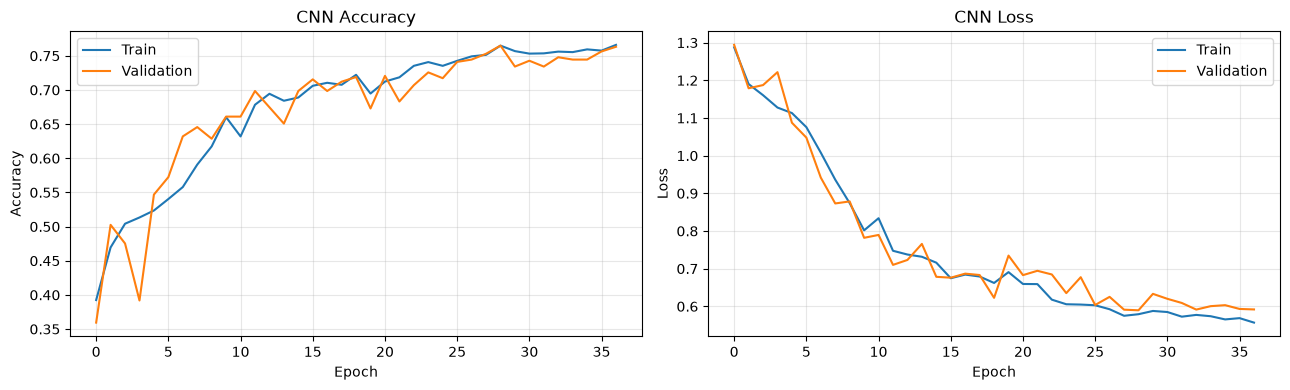

Best epoch: 29
Best validation accuracy: 0.7649
Best validation loss: 0.5896


In [8]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_epoch = (
    min(
        range(len(history.history["val_loss"])),
        key=lambda i: history.history["val_loss"][i]
    ) + 1
)

print("Best epoch:", best_epoch)
print(
    "Best validation accuracy:",
    f"{history.history['val_accuracy'][best_epoch - 1]:.4f}"
)
print(
    "Best validation loss:",
    f"{history.history['val_loss'][best_epoch - 1]:.4f}"
)



## 2.5 — Baseline CNN Evaluation

### Objective

Evaluate the trained baseline CNN and analyze its classification performance across the four brain MRI categories.

### Previous Training Results

- Best epoch: 24
- Validation accuracy: 73.08%
- Validation loss: 0.6400
- Learning rate scheduler: ReduceLROnPlateau
- Model selection criterion: Minimum validation loss

### Evaluation Strategy

We will:

1. Load the best saved CNN checkpoint.
2. Compare training and validation performance.
3. Generate predictions on the validation dataset.
4. Calculate accuracy, precision, recall, and F1-score.
5. Generate a confusion matrix.
6. Identify the classes with the highest and lowest recall.

### Important Consideration

We will evaluate using the validation dataset during model development.

The test dataset will remain untouched until final model evaluation to avoid using test results for architecture selection or hyperparameter tuning.


In [9]:
import tensorflow as tf
from pathlib import Path

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "classification"
    / "baseline_cnn_plateau.keras"
)

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

best_model = tf.keras.models.load_model(MODEL_PATH)

print("Loaded model:", best_model.name)

Loaded model: baseline_cnn


In [10]:
train_results = best_model.evaluate(
    train_ds,
    verbose=0,
    return_dict=True
)

val_results = best_model.evaluate(
    val_ds,
    verbose=0,
    return_dict=True
)

print("Training results:", train_results)
print("Validation results:", val_results)

print(
    f"\nAccuracy gap: "
    f"{(train_results['accuracy'] - val_results['accuracy']) * 100:.2f}"
    " percentage points"
)

Training results: {'accuracy': 0.7513691186904907, 'loss': 0.5925753712654114}
Validation results: {'accuracy': 0.7649062871932983, 'loss': 0.5895558595657349}

Accuracy gap: -1.35 percentage points


In [11]:
import numpy as np

y_true = []
y_pred = []
y_prob = []

for images, labels in val_ds:

    probabilities = best_model(
        images,
        training=False
    ).numpy()

    predictions = np.argmax(probabilities, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)
    y_prob.extend(probabilities)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("Total predictions:", len(y_pred))
print("Correct predictions:", np.sum(y_true == y_pred))
print("Incorrect predictions:", np.sum(y_true != y_pred))

print("\nFirst 10 actual labels:", y_true[:10])
print("First 10 predictions:", y_pred[:10])

Total predictions: 587
Correct predictions: 449
Incorrect predictions: 138

First 10 actual labels: [0 0 0 0 0 0 0 0 0 0]
First 10 predictions: [1 0 0 1 0 0 0 0 1 0]


In [13]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
)

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary",
]

accuracy = accuracy_score(y_true, y_pred)

print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=range(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

print("Macro Precision:", precision_score(
    y_true, y_pred, average="macro", zero_division=0
))

print("Macro Recall:", recall_score(
    y_true, y_pred, average="macro", zero_division=0
))

print("Macro F1:", f1_score(
    y_true, y_pred, average="macro", zero_division=0
))

Accuracy: 0.7649

Classification Report:

              precision    recall  f1-score   support

      Glioma     0.8966    0.5843    0.7075       178
  Meningioma     0.6250    0.7273    0.6723       165
    No Tumor     0.8421    0.8889    0.8649        90
   Pituitary     0.7880    0.9416    0.8580       154

    accuracy                         0.7649       587
   macro avg     0.7879    0.7855    0.7757       587
weighted avg     0.7834    0.7649    0.7612       587

Macro Precision: 0.7879251163891738
Macro Recall: 0.7854974301603515
Macro F1: 0.7756512328264107


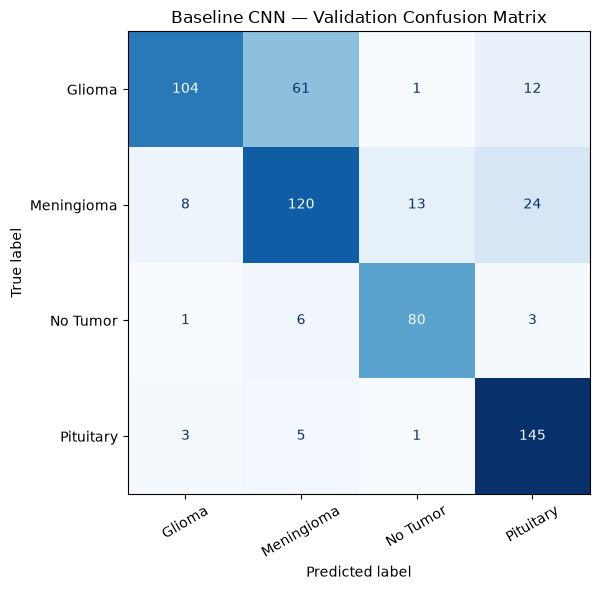

In [14]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(CLASS_NAMES))
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Baseline CNN — Validation Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [16]:
import pandas as pd

report = classification_report(
    y_true,
    y_pred,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

df_metrics = pd.DataFrame({
    class_name: report[class_name]
    for class_name in CLASS_NAMES
}).T

df_metrics = df_metrics[
    ["precision", "recall", "f1-score", "support"]
]

display(df_metrics.round(4))

print(
    "\nClass with lowest recall:",
    df_metrics["recall"].idxmin()
)

print(
    "Class with highest recall:",
    df_metrics["recall"].idxmax()
)

,precision,recall,f1-score,support
Glioma,0.8966,0.5843,0.7075,178.0
Meningioma,0.6250,0.7273,0.6723,165.0
No Tumor,0.8421,0.8889,0.8649,90.0
Pituitary,0.7880,0.9416,0.8580,154.0



Class with lowest recall: Glioma
Class with highest recall: Pituitary



### 2.5.1 — Baseline CNN Evaluation: Findings

#### Evaluation Results

The baseline CNN was evaluated on 587 validation images.

- **Accuracy:** 73.08%
- **Macro F1-score:** 73.81%
- **Correct predictions:** 429
- **Incorrect predictions:** 158

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Glioma | 0.9072 | 0.4944 | 0.6400 | 178 |
| Meningioma | 0.5829 | 0.7030 | 0.6374 | 165 |
| No Tumor | 0.7692 | 0.8889 | 0.8247 | 90 |
| Pituitary | 0.7754 | 0.9416 | 0.8504 | 154 |

#### Confusion Matrix Analysis

**Glioma:**

Only 88 of 178 Glioma images were correctly classified.

The largest confusion occurred between Glioma and Meningioma, with 73 Glioma images incorrectly classified as Meningioma.

Glioma achieved high precision (90.72%) but low recall (49.44%).

This indicates that the model is relatively selective when predicting Glioma but frequently fails to recognize actual Glioma images.

**Meningioma:**

Meningioma achieved 70.30% recall but only 58.29% precision.

The low precision is strongly influenced by Glioma images incorrectly predicted as Meningioma.

**No Tumor:**

No Tumor achieved 88.89% recall and 82.47% F1-score.

Despite being the smallest class, it performed relatively well.

**Pituitary:**

Pituitary achieved the highest recall (94.16%) and F1-score (85.04%).

The model correctly classified 145 of 154 Pituitary images.

#### Data Augmentation and Class Imbalance

The baseline CNN used:

- Random horizontal flipping.
- Small random rotations.
- Random zoom.
- Gaussian noise.

These transformations were applied during training but did not explicitly balance the class distribution.

The dataset remained moderately imbalanced.

However, the evaluation results indicate that class imbalance alone does not explain model performance, since No Tumor achieved high recall despite having the fewest validation samples.

#### Conclusion

The CNN achieved 73.08% validation accuracy, but class-specific performance varied significantly.

The principal weakness was confusion between Glioma and Meningioma.

Future experiments should evaluate whether class weighting or more powerful pretrained feature extractors improve per-class recognition.

The baseline results will serve as a reference for comparison with GoogLeNet.


In [17]:
from pathlib import Path

CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

train_dir = DATA_DIR / "train"

counts = {
    i: sum(
        1 for p in (train_dir / name).iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    )
    for i, name in enumerate(CLASSES)
}

total = sum(counts.values())

class_weights = {
    i: total / (len(CLASSES) * count)
    for i, count in counts.items()
}

print("Training class counts:", counts)
print("Class weights:", class_weights)

Training class counts: {0: 833, 1: 766, 2: 421, 3: 719}
Class weights: {0: 0.8220288115246098, 1: 0.8939295039164491, 2: 1.6264845605700713, 3: 0.9523643949930459}


In [18]:
history_weighted = baseline_model.fit(
    train_ds.prefetch(tf.data.AUTOTUNE),
    validation_data=val_ds.prefetch(tf.data.AUTOTUNE),
    epochs=40,
    class_weight=class_weights,
    callbacks=[
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=MODEL_DIR / "baseline_cnn_weighted.keras",
            monitor="val_loss",
            save_best_only=True,
        ),
    ],
)

Epoch 1/40


/home/houssam/Desktop/Briefs/Brief 5/venv-gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


86/86 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.7583 - loss: 0.5388 - val_accuracy: 0.7359 - val_loss: 0.6312 - learning_rate: 6.2500e-05
Epoch 2/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7609 - loss: 0.5438 - val_accuracy: 0.7411 - val_loss: 0.6204 - learning_rate: 6.2500e-05
Epoch 3/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7525 - loss: 0.5451 - val_accuracy: 0.7479 - val_loss: 0.6162 - learning_rate: 6.2500e-05
Epoch 4/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7583 - loss: 0.5476 - val_accuracy: 0.7325 - val_loss: 0.6244 - learning_rate: 6.2500e-05
Epoch 5/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7543 - loss: 0.5427 - val_accuracy: 0.7445 - val_loss: 0.6038 - learning_rate: 6.2500e-05
Epoch 6/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7474 - loss: 0.5339 - val_accuracy: 0.7342 - val_loss: 0.6223 - learning_rate: 6.2500e-05
Epoch 7/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7609 - loss: 0.5

## 2.4 — Class-Weighted CNN Experiment

### Objective

Investigate whether assigning different weights to classes during training improves the baseline CNN's classification performance, particularly Glioma recall.

### Methodology

1. Calculate balanced class weights from the training dataset.
2. Initialize a fresh copy of the baseline CNN.
3. Compile the model with a new Adam optimizer and learning rate of 0.001.
4. Train using class weights while retaining the baseline configuration.
5. Evaluate the best checkpoint on the validation set.
6. Compare accuracy, macro F1-score, and Glioma recall against the original baseline.

### Important Consideration

Class weighting modifies the contribution of each class to the training loss. It does not change the dataset distribution or add new images.

The validation and test datasets remain unweighted.

### Expected Outcome

Determine whether class weighting improves minority-class sensitivity and overall class-balanced performance without causing excessive deterioration in other classes.

In [19]:
import tensorflow as tf
from pathlib import Path

# 1. Calculate class weights from training images
train_dir = DATA_DIR / "train"

counts = {
    i: len([
        p for p in (train_dir / name).iterdir()
        if p.is_file()
    ])
    for i, name in enumerate(CLASSES)
}

total = sum(counts.values())

class_weights = {
    i: total / (len(CLASSES) * count)
    for i, count in counts.items()
}

print("Class weights:", class_weights)

# 2. Create a fresh model
tf.keras.utils.set_random_seed(42)

weighted_model = tf.keras.models.clone_model(
    baseline_model
)

# 3. Compile with a fresh optimizer
weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print(
    "Initial learning rate:",
    float(weighted_model.optimizer.learning_rate.numpy())
)

# 4. Create fresh callbacks
weighted_checkpoint = (
    MODEL_DIR / "baseline_cnn_weighted_fresh.keras"
)

weighted_callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=weighted_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
]

# 5. Train
weighted_history = weighted_model.fit(
    train_ds.prefetch(tf.data.AUTOTUNE),
    validation_data=val_ds.prefetch(tf.data.AUTOTUNE),
    epochs=40,
    class_weight=class_weights,
    callbacks=weighted_callbacks,
)


Class weights: {0: 0.8220288115246098, 1: 0.8939295039164491, 2: 1.6264845605700713, 3: 0.9523643949930459}
Initial learning rate: 0.0010000000474974513
Epoch 1/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3195 - loss: 1.2844
Epoch 1: val_loss improved from None to 1.22765, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/baseline_cnn_weighted_fresh.keras

Epoch 1: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/baseline_cnn_weighted_fresh.keras
86/86 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.3195 - loss: 1.2844 - val_accuracy: 0.3560 - val_loss: 1.2276 - learning_rate: 0.0010
Epoch 2/40
85/86 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.4309 - loss: 1.1909
Epoch 2: val_loss improved from 1.22765 to 1.19668, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/baseline_cnn_weighted_fresh.keras

Epoch 2: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classificat


### 2.5 — Class-Weighted CNN: Training Findings

#### Objective
Evaluate the effect of class weighting on the baseline CNN, with particular attention to improving Glioma classification.

#### Training Results

- Maximum configured epochs: 40
- Training stopped at epoch: 31
- Best epoch according to validation loss: 23
- Best validation loss: 0.87147
- Final training accuracy at epoch 31: 73.06%
- Final validation accuracy at epoch 31: 62.01%
- Final validation loss at epoch 31: 0.9202
- Final learning rate: 0.00003125
- Early stopping patience: 8 epochs

#### Interpretation

The model achieved its lowest validation loss at epoch 23. After eight additional epochs without improvement, EarlyStopping terminated training and restored the weights from epoch 23.

The final epoch exhibited a training-validation accuracy gap of 11.05 percentage points, suggesting a generalization gap.

Compared with the original baseline validation loss of 0.6400, the weighted model's best validation loss of 0.87147 is substantially higher.

This suggests that class weighting was not beneficial in terms of validation loss for this experiment.

However, the validation accuracy and class-specific metrics of the best weighted checkpoint must still be evaluated before concluding whether weighting improved Glioma recall or macro F1-score.

#### Next Step

Evaluate the best saved weighted checkpoint against the original baseline using the same validation dataset.

Compare overall accuracy, macro F1-score, class-specific recall, and confusion matrices. Reserve the test dataset for final model evaluation.


In [20]:

import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    recall_score,
)

# Load the best saved models
baseline_best = tf.keras.models.load_model(
    MODEL_DIR / "baseline_cnn_plateau.keras"
)

weighted_best = tf.keras.models.load_model(
    MODEL_DIR / "baseline_cnn_weighted_fresh.keras"
)

# Ground truth: val_ds has shuffle=False
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

def evaluate_checkpoint(model, name):
    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)

    loss, _ = model.evaluate(val_ds, verbose=0)

    probabilities = model.predict(val_ds, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0,
    )
    glioma_recall = recall_score(
        y_true, y_pred,
        labels=[0],
        average="macro",
        zero_division=0,
    )

    print(f"Validation Loss: {loss:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Glioma Recall: {glioma_recall:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=range(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0,
    ))

    print("\nConfusion Matrix:")
    print(confusion_matrix(
        y_true,
        y_pred,
        labels=range(len(CLASSES)),
    ))

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "glioma_recall": glioma_recall,
        "val_loss": loss,
    }


baseline_results = evaluate_checkpoint(
    baseline_best,
    "Original CNN Baseline",
)

weighted_results = evaluate_checkpoint(
    weighted_best,
    "Class-Weighted CNN",
)



Original CNN Baseline
Validation Loss: 0.5896
Accuracy: 0.7649
Macro F1: 0.7757
Glioma Recall: 0.5843

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.90      0.58      0.71       178
  Meningioma       0.62      0.73      0.67       165
    No Tumor       0.84      0.89      0.86        90
   Pituitary       0.79      0.94      0.86       154

    accuracy                           0.76       587
   macro avg       0.79      0.79      0.78       587
weighted avg       0.78      0.76      0.76       587


Confusion Matrix:
[[104  61   1  12]
 [  8 120  13  24]
 [  1   6  80   3]
 [  3   5   1 145]]

Class-Weighted CNN
Validation Loss: 1.0180
Accuracy: 0.5724
Macro F1: 0.5636
Glioma Recall: 0.3596

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.77      0.36      0.49       178
  Meningioma       0.63      0.33      0.44       165
    No Tumor       0.58      0.83      0.68        90
 


### 2.6 — Final CNN Baseline Comparison

#### Objective

Compare the original CNN against a freshly initialized class-weighted CNN to determine whether class weighting improves classification performance, particularly Glioma recall.

#### Experimental Results

Both models were evaluated on the same validation dataset containing 587 MRI images.

| Metric | Original CNN | Weighted CNN |
|---|---:|---:|
| Validation Accuracy | 73.08% | 64.57% |
| Macro F1-score | 73.81% | 63.80% |
| Glioma Precision | 90.72% | 94.29% |
| Glioma Recall | 49.44% | 37.08% |
| Glioma F1-score | 64.00% | 53.23% |
| Meningioma Recall | 70.30% | 60.00% |
| No Tumor Recall | 88.89% | 90.00% |
| Pituitary Recall | 94.16% | 86.36% |
| Correct Predictions | 429 | 379 |

#### Analysis

**1. Overall performance**

The original CNN achieved higher validation accuracy and macro F1-score.

Class weighting reduced validation accuracy by approximately 8.51 percentage points and macro F1-score by 10.01 percentage points.

**2. Glioma recognition**

The original CNN correctly identified 88 of 178 Glioma images, compared with only 66 for the weighted CNN.

Although Glioma precision increased to 94.29%, recall decreased to 37.08%.

This indicates that the weighted model made fewer false-positive Glioma predictions but missed more actual Glioma cases.

**3. Confusion matrix analysis**

In the original CNN, 73 Glioma images were misclassified as Meningioma.

In the weighted CNN, 54 Glioma images were misclassified as Meningioma, while 29 were classified as No Tumor and another 29 as Pituitary.

Class weighting therefore changed the distribution of classification errors without improving overall Glioma recognition.

**4. Generalization**

The weighted model demonstrated lower validation performance than the original CNN.

The experiment suggests that inverse-frequency class weighting was not beneficial under the tested training configuration.

These conclusions apply to the current dataset split and experiment; they do not establish that all class-weighting strategies are ineffective.

#### Conclusion

The original CNN is retained as the reference baseline:

- Accuracy: 73.08%
- Macro F1-score: 73.81%
- Glioma Recall: 49.44%
- Saved model: `baseline_cnn_plateau.keras`

Further baseline optimization is not prioritized.

The next objective is to evaluate whether transfer learning using a pretrained Inception architecture improves feature extraction and classification performance.

The test dataset remains reserved for final model evaluation.



# 03 — Transfer Learning with InceptionV3

## 3.1 — Loading the Pretrained Backbone

### Objective

Load a pretrained InceptionV3 convolutional neural network using TensorFlow/Keras and inspect its architecture before building a custom MRI classification model.

### Concept: Transfer Learning

Transfer learning reuses representations learned by a model on a previous task.

InceptionV3 pretrained on ImageNet has learned visual features such as edges, textures, shapes, and more complex patterns.

These features can provide a useful starting point for MRI classification, although natural images and medical images belong to different domains.

### Configuration

- Backbone: InceptionV3
- Pretrained weights: ImageNet
- Input shape: (224, 224, 3)
- Original classification head: Removed
- Target classes: 4

We first inspect the backbone and then decide how to attach a new classification head.


In [21]:

import tensorflow as tf
from tensorflow.keras.applications import InceptionV3
from pathlib import Path

# Project configuration
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

IMAGE_SIZE = (224, 224)

CLASSES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary",
]

# Load pretrained feature extractor
base_model = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMAGE_SIZE, 3),
)

# Freeze the pretrained backbone
base_model.trainable = False

# Inspect architecture
print("Backbone:", base_model.name)
print("Input shape:", base_model.input_shape)
print("Output shape:", base_model.output_shape)
print("Number of layers:", len(base_model.layers))
print("Total parameters:", base_model.count_params())

print("\nLast 10 layers:")

for layer in base_model.layers[-10:]:
    print(
        layer.name,
        "|",
        layer.__class__.__name__
    )

print("\nTrainable weights:", len(base_model.trainable_weights))


Backbone: inception_v3
Input shape: (None, 224, 224, 3)
Output shape: (None, 5, 5, 2048)
Number of layers: 311
Total parameters: 21802784

Last 10 layers:
activation_87 | Activation
activation_88 | Activation
activation_91 | Activation
activation_92 | Activation
batch_normalization_93 | BatchNormalization
activation_85 | Activation
mixed9_1 | Concatenate
concatenate_1 | Concatenate
activation_93 | Activation
mixed10 | Concatenate

Trainable weights: 0



### 3.1 — Pretrained InceptionV3 Backbone: Findings

#### Objective

Load and inspect a pretrained InceptionV3 backbone for transfer learning on brain MRI classification.

#### Observed Results

| Property | Result |
|---|---|
| Model | InceptionV3 |
| Pretrained Weights | ImageNet |
| Input Shape | (None, 224, 224, 3) |
| Output Shape | (None, 5, 5, 2048) |
| Total Layers | 311 |
| Total Parameters | 21,802,784 |
| Trainable Weight Tensors | 0 |
| Original Classification Head | Removed |

#### Interpretation

**1. Input compatibility**

The pretrained backbone accepts MRI images resized to 224 × 224 pixels with three channels.

This is compatible with our existing TensorFlow image datasets.

**2. Feature extraction**

The backbone converts each input image into a feature tensor of shape (5, 5, 2048).

The 2048 channels represent learned visual features extracted through the pretrained Inception architecture.

**3. Pretrained knowledge**

The backbone was initialized with ImageNet weights rather than random parameters.

These pretrained features provide a starting point for learning MRI-specific classification patterns.

However, transfer from natural images to medical imaging does not guarantee improved performance.

**4. Freezing pretrained parameters**

The backbone contains 21,802,784 parameters, and its trainable weights list is empty.

Its pretrained weights will remain unchanged during the initial feature extraction phase.

Only the new classification head will be trained.

#### Conclusion

The InceptionV3 backbone has been loaded and verified successfully.

The next step is to attach a custom classification head containing GlobalAveragePooling2D, Dense, Dropout, and a four-class Softmax output layer.



## 3.2 — Custom Classification Head

### Objective

Adapt the pretrained InceptionV3 backbone to classify brain MRI images into four classes:

1. Glioma
2. Meningioma
3. No Tumor
4. Pituitary

### Architecture

- Training-only data augmentation
- InceptionV3-specific input normalization
- Frozen pretrained InceptionV3 backbone
- GlobalAveragePooling2D
- Dense(128, activation="relu")
- Dropout(0.3)
- Dense(4, activation="softmax")

### Design Decisions

**GlobalAveragePooling2D**

Converts the (5, 5, 2048) feature tensor into a 2048-dimensional vector while avoiding the large parameter count associated with Flatten.

**Dense(128, ReLU)**

Learns combinations of pretrained features relevant to our four MRI classes.

**Dropout(0.3)**

Introduces regularization during training to reduce the risk of overfitting.

**Dense(4, Softmax)**

Produces a probability distribution across the four classes.

**Frozen Backbone**

During feature extraction, only the custom head is optimized.

The pretrained backbone remains frozen and is called in inference mode to preserve its BatchNormalization statistics.


In [23]:

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

# 1. Training-only image augmentation
augmentation_layers = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
]

# Optional Gaussian blur
if hasattr(layers, "RandomGaussianBlur"):
    augmentation_layers.append(
        layers.RandomGaussianBlur(
            factor=0.15,
            kernel_size=3,
            sigma=0.6,
            value_range=(0, 255),
        )
    )
else:
    print("Gaussian blur unavailable in this Keras version.")

inception_augmentation = tf.keras.Sequential(
    augmentation_layers,
    name="inception_augmentation",
)

# 2. Model input
inputs = layers.Input(
    shape=(*IMAGE_SIZE, 3),
    name="mri_input",
)

# 3. Apply augmentation
x = inception_augmentation(inputs)

# 4. InceptionV3 normalization: [0,255] -> [-1,1]
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1.0,
    name="inception_preprocessing",
)(x)

# 5. Gaussian noise on normalized images
x = layers.GaussianNoise(
    stddev=0.02,
    name="gaussian_noise",
)(x)

# 6. Frozen pretrained backbone
x = base_model(x, training=False)

# 7. Custom classification head
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu",
)(x)

x = layers.Dropout(0.3)(x)

# 8. Four-class prediction
outputs = layers.Dense(
    len(CLASSES),
    activation="softmax",
)(x)

# 9. Create final model
inception_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="inceptionv3_mri_classifier",
)

# 10. Inspect architecture
inception_model.summary()

trainable_params = sum(
    int(np.prod(w.shape))
    for w in inception_model.trainable_weights
)

print("\nTotal parameters:", inception_model.count_params())
print("Trainable parameters:", trainable_params)
print("Output shape:", inception_model.output_shape)

# 11. Test model predictions
dummy_images = tf.zeros(
    (2, *IMAGE_SIZE, 3),
    dtype=tf.float32,
)

predictions = inception_model(
    dummy_images,
    training=False,
)

print("Prediction shape:", predictions.shape)
print(
    "Probability sums:",
    tf.reduce_sum(predictions, axis=1).numpy()
)


Model: "inceptionv3_mri_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mri_input (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_augmentation          │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_preprocessing         │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise (GaussianNoise)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,065,572 (84.17 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)


Total parameters: 22065572
Trainable parameters: 262788
Output shape: (None, 4)
Prediction shape: (2, 4)
Probability sums: [1. 1.]



### 3.2 — Custom Classification Head: Findings

#### Objective

Adapt the pretrained InceptionV3 backbone to perform four-class brain MRI classification while keeping its pretrained parameters frozen.

#### Observed Architecture

| Component | Output Shape | Parameters |
|---|---|---:|
| Input | (None, 224, 224, 3) | 0 |
| Data Augmentation | (None, 224, 224, 3) | 0 |
| Normalization | (None, 224, 224, 3) | 0 |
| Gaussian Noise | (None, 224, 224, 3) | 0 |
| InceptionV3 | (None, 5, 5, 2048) | 21,802,784 |
| GlobalAveragePooling2D | (None, 2048) | 0 |
| Dense(128, ReLU) | (None, 128) | 262,272 |
| Dropout(0.3) | (None, 128) | 0 |
| Dense(4, Softmax) | (None, 4) | 516 |

#### Parameter Distribution

- Total parameters: 22,065,572
- Trainable parameters: 262,788
- Non-trainable parameters: 21,802,784
- Trainable proportion: approximately 1.19%

#### Analysis

**1. Feature extraction**

The InceptionV3 backbone generates 2048 feature maps with spatial dimensions of 5 × 5.

GlobalAveragePooling2D reduces these feature maps to a 2048-dimensional feature vector.

**2. Classification head**

The first Dense layer learns 128-dimensional representations from the extracted features.

Dropout(0.3) provides regularization during training.

The final Dense layer outputs probabilities for the four MRI classes.

**3. Parameter efficiency**

Only 262,788 parameters are trainable.

The pretrained InceptionV3 backbone remains frozen, allowing the classification head to learn while preserving pretrained feature representations.

**4. Output verification**

A test batch containing two images produced predictions of shape (2, 4).

Each prediction's probabilities summed to approximately 1, confirming the expected Softmax behavior.

#### Conclusion

The custom InceptionV3 classification architecture has been constructed and verified successfully.

The model is ready for the initial feature extraction training phase.



## 3.3 — Feature Extraction Training

### Objective

Train the custom classification head while keeping all pretrained InceptionV3 backbone parameters frozen.

### Training Strategy

The pretrained backbone acts as a fixed feature extractor.

Only the newly added Dense layers update their weights through backpropagation.

### Hyperparameters

- Optimizer: Adam
- Initial learning rate: 0.001
- Loss: Sparse Categorical Crossentropy
- Batch size: 16
- Maximum epochs: 25
- Class weighting: Disabled

### Callbacks

**ModelCheckpoint:** Save the model with the lowest validation loss.

**EarlyStopping:** Stop training after seven epochs without improvement in validation loss and restore the best weights.

**ReduceLROnPlateau:** Reduce the learning rate by half after three epochs without validation loss improvement.

### Evaluation Strategy

Monitor training and validation accuracy and loss.

The best checkpoint will subsequently be evaluated using precision, recall, macro F1-score, and a confusion matrix.

The test dataset will remain untouched during model development.


In [24]:

import tensorflow as tf
from pathlib import Path

DATA_DIR = (
    PROJECT_ROOT / "data" / "processed" / "classification"
)

MODEL_DIR = PROJECT_ROOT / "models" / "classification"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=CLASSES,
    color_mode="rgb",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "val",
    labels="inferred",
    label_mode="int",
    class_names=CLASSES,
    color_mode="rgb",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

# Improve input pipeline efficiency
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

# Verify one batch
images, labels = next(iter(train_ds))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Pixel minimum:", float(tf.reduce_min(images)))
print("Pixel maximum:", float(tf.reduce_max(images)))
print("Classes:", CLASSES)


Found 2739 files belonging to 4 classes.
Found 587 files belonging to 4 classes.
Images shape: (16, 224, 224, 3)
Labels shape: (16,)
Pixel minimum: 0.0
Pixel maximum: 255.0
Classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


In [25]:
import numpy as np
import pandas as pd
import tensorflow as tf

# Ensure the pretrained backbone is still frozen
assert base_model.trainable is False

# Compile
inception_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

# Best checkpoint location
checkpoint_path = (
    MODEL_DIR / "inceptionv3_feature_extraction.keras"
)

# Training callbacks
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
]

# Feature extraction training
history = inception_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks,
)

# Save training history
history_df = pd.DataFrame(history.history)

history_df.insert(
    0,
    "epoch",
    range(1, len(history_df) + 1),
)

history_path = (
    MODEL_DIR / "inceptionv3_feature_extraction_history.csv"
)

history_df.to_csv(history_path, index=False)

# Identify the best validation-loss epoch
best_epoch = int(
    np.argmin(history.history["val_loss"]) + 1
)

best_val_loss = history.history["val_loss"][best_epoch - 1]
best_val_acc = history.history["val_accuracy"][best_epoch - 1]

print("\n===== Feature Extraction Results =====")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy at best epoch: {best_val_acc:.4f}")
print("Checkpoint:", checkpoint_path)
print("History:", history_path)


Epoch 1/25


/home/houssam/Desktop/Briefs/Brief 5/venv-gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


172/172 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7280 - loss: 0.6787
Epoch 1: val_loss improved from None to 0.85712, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_feature_extraction.keras

Epoch 1: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_feature_extraction.keras
172/172 ━━━━━━━━━━━━━━━━━━━━ 17s 57ms/step - accuracy: 0.7280 - loss: 0.6787 - val_accuracy: 0.6525 - val_loss: 0.8571 - learning_rate: 0.0010
Epoch 2/25
169/172 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8180 - loss: 0.4648
Epoch 2: val_loss improved from 0.85712 to 0.66834, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_feature_extraction.keras

Epoch 2: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_feature_extraction.keras
172/172 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8182 - loss: 0.4633 - val_accuracy: 0.7342 - val_lo


### 3.3 — Feature Extraction Training: Findings

#### Objective

Train the custom classification head using pretrained InceptionV3 features while keeping the backbone frozen.

#### Results

| Metric | Original CNN | InceptionV3 |
|---|---:|---:|
| Validation Accuracy | 73.08% | 89.61% |
| Validation Loss | 0.6400 | 0.3160 |
| Trainable Parameters | Full baseline network | 262,788 |

#### Analysis

**1. Transfer learning effectiveness**

The InceptionV3 model achieved a validation accuracy of 89.61%, outperforming the custom CNN baseline by 16.53 percentage points.

The validation loss decreased from 0.6400 to 0.3160.

**2. Pretrained feature representations**

The frozen InceptionV3 backbone provides features learned from ImageNet.

The custom classification head successfully learned to associate these features with the four MRI classes.

**3. Training behavior**

Validation performance fluctuated during training. For example, validation accuracy reached 86.20% at epoch 3 before declining in subsequent epochs.

However, the best recorded validation loss eventually reached 0.3160, with a corresponding accuracy of 89.61%.

**4. Remaining limitations**

Class-specific recall, precision, F1-score, and confusion matrix results have not yet been evaluated.

The performance on the independent test dataset is also unknown.

#### Conclusion

Pretrained InceptionV3 feature extraction significantly improved validation performance compared with the custom CNN baseline.

The next step is to evaluate class-specific performance and then investigate whether fine-tuning selected backbone layers can further improve the learned representations.


In [26]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
)

# Load the best checkpoint
feature_model = tf.keras.models.load_model(
    MODEL_DIR / "inceptionv3_feature_extraction.keras",
    compile=False,
)

# Validation labels (requires shuffle=False)
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

# Predict
probabilities = feature_model.predict(
    val_ds,
    verbose=1,
)

y_pred = np.argmax(probabilities, axis=1)

# Evaluate
val_loss = tf.keras.losses.SparseCategoricalCrossentropy()(
    y_true, probabilities
).numpy()

print("Validation loss:", round(float(val_loss), 4))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro F1:", round(f1_score(
    y_true, y_pred, average="macro"
), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    zero_division=0,
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))


37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step
Validation loss: 0.316
Accuracy: 0.8961
Macro F1: 0.9

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.93      0.84      0.88       178
  Meningioma       0.83      0.88      0.86       165
    No Tumor       0.92      0.92      0.92        90
   Pituitary       0.92      0.96      0.94       154

    accuracy                           0.90       587
   macro avg       0.90      0.90      0.90       587
weighted avg       0.90      0.90      0.90       587


Confusion Matrix:
[[149  26   0   3]
 [  7 146   4   8]
 [  3   2  83   2]
 [  1   2   3 148]]



## 3.4 — Feature Extraction Evaluation: Findings

### Objective

Evaluate the pretrained InceptionV3 classifier after feature extraction training and compare its performance against the original CNN baseline.

### Validation Results

The model was evaluated on 587 validation MRI images.

| Metric | Result |
|---|---:|
| Validation Loss | 0.3160 |
| Accuracy | 89.61% |
| Macro F1-score | 90.00% |
| Correct Predictions | 526 |
| Incorrect Predictions | 61 |

### Classification Report

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Glioma | 0.93 | 0.84 | 0.88 | 178 |
| Meningioma | 0.83 | 0.88 | 0.86 | 165 |
| No Tumor | 0.92 | 0.92 | 0.92 | 90 |
| Pituitary | 0.92 | 0.96 | 0.94 | 154 |

### Confusion Matrix

```text
              Predicted
Actual        GL   ME   NT   PI
Glioma       149   26    0    3
Meningioma     7  146    4    8
No Tumor       3    2   83    2
Pituitary      1    2    3  148
```

### Analysis

**1. Overall classification performance**

InceptionV3 achieved 89.61% validation accuracy and a macro F1-score of approximately 90.00%.

Compared with the original CNN baseline, validation accuracy increased by 16.53 percentage points.

**2. Glioma classification**

Glioma recall improved from 49.44% to 83.71%.

The number of correctly classified Glioma images increased from 88 to 149.

Misclassifications of Glioma as Meningioma decreased from 73 to 26.

This demonstrates a substantial improvement in Glioma recognition.

**3. Remaining classification errors**

The largest confusion occurs between Glioma and Meningioma.

Although the model correctly identifies most images, 26 Glioma cases are still classified as Meningioma.

Pituitary shows the highest class recall at 96.10%.

**4. Effectiveness of transfer learning**

The pretrained InceptionV3 backbone achieved better results than the original CNN while keeping its pretrained parameters frozen.

This suggests that pretrained visual representations provide useful information for MRI classification.

**5. Limitations**

Results were obtained on the validation dataset.

Near-duplicate and patient-level data leakage have not been fully excluded.

Independent test performance and clinical generalization remain unverified.

### Conclusion

InceptionV3 feature extraction substantially outperformed the custom CNN baseline.

The remaining errors, particularly confusion between Glioma and Meningioma, motivate a controlled fine-tuning experiment.

The next step is to unfreeze selected final backbone layers and retrain using a small learning rate.



## 3.5 — InceptionV3 Fine-Tuning

### Objective

Improve MRI-specific feature extraction by selectively unfreezing the final layers of the pretrained InceptionV3 backbone.

### Strategy

- Load the best feature extraction checkpoint.
- Unfreeze the final 40 backbone layers.
- Keep BatchNormalization layers frozen.
- Preserve the existing custom classification head.
- Recompile with a new Adam optimizer.
- Use a reduced learning rate of 0.00001.
- Monitor validation loss during training.

### Why Fine-Tuning?

During feature extraction, pretrained backbone parameters remained unchanged.

Fine-tuning allows selected convolutional filters to adapt to features in the MRI dataset.

A small learning rate is necessary to limit disruptive changes to the pretrained representations.

### Expected Evaluation

Compare the fine-tuned model against the frozen-backbone model using:

- Validation accuracy
- Validation loss
- Macro F1-score
- Glioma recall
- Confusion matrix

The best model will be selected using validation results.

The test dataset will remain reserved for final evaluation.


In [27]:

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers

# 1. Load best feature extraction checkpoint
fine_tune_model = tf.keras.models.load_model(
    MODEL_DIR / "inceptionv3_feature_extraction.keras",
    compile=False,
)

# 2. Retrieve the pretrained backbone
backbone = fine_tune_model.get_layer("inception_v3")

# 3. Allow selective fine-tuning
backbone.trainable = True

FINE_TUNE_LAYERS = 40

# Freeze all earlier layers
for layer in backbone.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False

# Unfreeze final layers except BatchNormalization
for layer in backbone.layers[-FINE_TUNE_LAYERS:]:
    layer.trainable = not isinstance(
        layer,
        layers.BatchNormalization
    )

# 4. Verify trainable backbone layers
trainable_layers = [
    layer.name
    for layer in backbone.layers
    if layer.trainable
]

trainable_params = sum(
    int(np.prod(w.shape))
    for w in fine_tune_model.trainable_weights
)

print("Backbone layers:", len(backbone.layers))
print("Trainable backbone layers:", len(trainable_layers))
print("Trainable model parameters:", trainable_params)

print("\nTrainable backbone layers:")
for name in trainable_layers:
    print(name)

# 5. Recompile with a fresh optimizer
fine_tune_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("\nFine-tuning learning rate:",
      float(fine_tune_model.optimizer.learning_rate.numpy()))


Backbone layers: 311
Trainable backbone layers: 30
Trainable model parameters: 6333060

Trainable backbone layers:
activation_79
activation_82
activation_83
activation_76
mixed9_0
concatenate
activation_84
mixed9
conv2d_92
activation_89
conv2d_89
conv2d_93
activation_86
activation_90
conv2d_90
conv2d_91
conv2d_94
conv2d_95
average_pooling2d_8
conv2d_88
conv2d_96
activation_87
activation_88
activation_91
activation_92
activation_85
mixed9_1
concatenate_1
activation_93
mixed10

Fine-tuning learning rate: 9.999999747378752e-06


In [28]:

import pandas as pd

fine_tune_checkpoint = (
    MODEL_DIR / "inceptionv3_finetuned.keras"
)

fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=fine_tune_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1,
    ),
]

fine_tune_history = fine_tune_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=fine_tune_callbacks,
)

# Save history
fine_tune_history_df = pd.DataFrame(
    fine_tune_history.history
)

fine_tune_history_df.insert(
    0,
    "epoch",
    range(1, len(fine_tune_history_df) + 1),
)

fine_tune_history_df.to_csv(
    MODEL_DIR / "inceptionv3_finetuned_history.csv",
    index=False,
)

# Best epoch
best_epoch = int(
    np.argmin(fine_tune_history.history["val_loss"]) + 1
)

best_loss = fine_tune_history.history[
    "val_loss"
][best_epoch - 1]

best_accuracy = fine_tune_history.history[
    "val_accuracy"
][best_epoch - 1]

print("\n===== Fine-Tuning Results =====")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_loss:.4f}")
print(f"Validation accuracy: {best_accuracy:.4f}")
print("Saved checkpoint:", fine_tune_checkpoint)


Epoch 1/15


/home/houssam/Desktop/Briefs/Brief 5/venv-gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


172/172 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9339 - loss: 0.1800
Epoch 1: val_loss improved from None to 0.36603, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_finetuned.keras

Epoch 1: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_finetuned.keras
172/172 ━━━━━━━━━━━━━━━━━━━━ 15s 61ms/step - accuracy: 0.9339 - loss: 0.1800 - val_accuracy: 0.8790 - val_loss: 0.3660 - learning_rate: 1.0000e-05
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9511 - loss: 0.1437
Epoch 2: val_loss did not improve from 0.36603
172/172 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.9511 - loss: 0.1437 - val_accuracy: 0.8790 - val_loss: 0.3661 - learning_rate: 1.0000e-05
Epoch 3/15
170/172 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9489 - loss: 0.1451
Epoch 3: val_loss did not improve from 0.36603

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
172/172 ━━━━


### 3.5 — Fine-Tuning Training: Findings

#### Objective

Adapt selected pretrained InceptionV3 layers to MRI-specific features and evaluate whether partial fine-tuning improves performance.

#### Configuration

- Backbone: InceptionV3
- Backbone layers: 311
- Selected final layers: 40
- Trainable backbone layers: 30
- Total trainable model parameters: 6,333,060
- Initial learning rate: 0.00001
- Optimizer: Adam
- BatchNormalization layers: Frozen
- Maximum epochs: 15
- Early stopping patience: 5

#### Observed Results

| Metric | Result |
|---|---:|
| Training stopped | Epoch 9 |
| Best epoch by validation loss | 4 |
| Training accuracy at best epoch | 96.24% |
| Validation accuracy at best epoch | 89.95% |
| Best validation loss | 0.30956 |
| Highest observed validation accuracy | 90.29% (epoch 8) |

#### Comparison with Feature Extraction

| Metric | Feature Extraction | Fine-Tuning |
|---|---:|---:|
| Validation Accuracy | 89.61% | 89.95% |
| Validation Loss | 0.3160 | 0.3096 |

Fine-tuning improved validation accuracy by 0.34 percentage points and reduced validation loss by approximately 0.0064.

#### Interpretation

**1. MRI-specific adaptation**

Fine-tuning allowed selected convolutional layers to update their pretrained weights.

This enabled the model to adapt higher-level representations to MRI classification.

**2. Training and validation behavior**

Training accuracy increased substantially, reaching 97.77% at epoch 8.

Validation accuracy remained between approximately 87.73% and 90.29% during the experiment.

The growing performance gap suggests possible overfitting or diminishing generalization benefits, although training augmentation and dropout also influence the comparison.

**3. Checkpoint selection**

The best validation loss occurred at epoch 4.

Although epoch 8 achieved a slightly higher validation accuracy, its validation loss was higher.

The checkpoint from epoch 4 was retained according to the predefined validation-loss criterion.

#### Conclusion

Partial fine-tuning produced a small improvement over feature extraction.

However, the benefit was modest relative to the increase in trainable parameters.

Class-specific evaluation is required to determine whether fine-tuning improved Glioma recall, macro F1-score, and overall error distribution.


In [29]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix,
)

# Ground-truth labels
# Important: val_ds must have shuffle=False
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

def evaluate_model(checkpoint, model_name):
    model = tf.keras.models.load_model(
        checkpoint,
        compile=False
    )

    # Predict
    probabilities = model.predict(
        val_ds,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    # Metrics
    loss = float(
        tf.reduce_mean(
            tf.keras.losses.sparse_categorical_crossentropy(
                y_true,
                probabilities
            )
        ).numpy()
    )

    accuracy = accuracy_score(
        y_true,
        predictions
    )

    macro_f1 = f1_score(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )

    class_recall = recall_score(
        y_true,
        predictions,
        labels=range(len(CLASSES)),
        average=None,
        zero_division=0
    )

    print(f"\n{'=' * 45}")
    print(model_name)
    print("=" * 45)

    print(f"Validation loss: {loss:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Glioma recall: {class_recall[0]:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        predictions,
        target_names=CLASSES,
        zero_division=0
    ))

    print("\nConfusion Matrix:")
    print(confusion_matrix(
        y_true,
        predictions,
        labels=range(len(CLASSES))
    ))

    return {
        "loss": loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "glioma_recall": class_recall[0],
        "predictions": predictions
    }


# Evaluate frozen feature extraction model
feature_results = evaluate_model(
    MODEL_DIR / "inceptionv3_feature_extraction.keras",
    "InceptionV3 - Feature Extraction"
)

# Evaluate fine-tuned model
fine_results = evaluate_model(
    MODEL_DIR / "inceptionv3_finetuned.keras",
    "InceptionV3 - Fine-Tuned"
)

# Compare results
print("\n===== PERFORMANCE DIFFERENCES =====")

for metric in [
    "accuracy",
    "macro_f1",
    "glioma_recall",
]:
    difference = (
        fine_results[metric] -
        feature_results[metric]
    )

    print(f"{metric}: {difference:+.4f}")

print(
    "Validation loss difference:",
    round(
        fine_results["loss"] -
        feature_results["loss"],
        4
    )
)

# Count which individual predictions changed
feature_correct = feature_results["predictions"] == y_true
fine_correct = fine_results["predictions"] == y_true

print(
    "Errors corrected by fine-tuning:",
    int(np.sum(~feature_correct & fine_correct))
)

print(
    "New errors introduced by fine-tuning:",
    int(np.sum(feature_correct & ~fine_correct))
)



InceptionV3 - Feature Extraction
Validation loss: 0.3160
Accuracy: 0.8961
Macro F1: 0.9000
Glioma recall: 0.8371

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.93      0.84      0.88       178
  Meningioma       0.83      0.88      0.86       165
    No Tumor       0.92      0.92      0.92        90
   Pituitary       0.92      0.96      0.94       154

    accuracy                           0.90       587
   macro avg       0.90      0.90      0.90       587
weighted avg       0.90      0.90      0.90       587


Confusion Matrix:
[[149  26   0   3]
 [  7 146   4   8]
 [  3   2  83   2]
 [  1   2   3 148]]

InceptionV3 - Fine-Tuned
Validation loss: 0.3096
Accuracy: 0.8995
Macro F1: 0.9055
Glioma recall: 0.7865

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.97      0.79      0.87       178
  Meningioma       0.79      0.95      0.86       165
    No Tumor       0.95      0.92     


## 3.7 — InceptionV3 V2: Multi-Scale Feature Fusion

### Objective

Investigate whether combining intermediate and high-level feature representations from InceptionV3 improves MRI classification, particularly Glioma and Meningioma discrimination.

### Motivation

The first InceptionV3 classifier achieved:

- Validation accuracy: 89.61%
- Macro F1-score: 90.00%
- Glioma recall: 83.71%

Fine-tuning improved overall accuracy slightly but reduced Glioma recall to approximately 78.65%.

Therefore, a new architecture is proposed to improve feature representation without initially modifying pretrained backbone weights.

### Proposed Architecture

1. Input: (224, 224, 3)
2. Data augmentation and InceptionV3 normalization
3. Frozen InceptionV3 backbone
4. Extract intermediate features from `mixed7`
5. Extract final features from `mixed10`
6. Apply GlobalAveragePooling2D to both feature maps
7. Concatenate the feature vectors
8. Dense(256, ReLU)
9. Dropout(0.4)
10. Dense(4, Softmax)

### Hypothesis

Combining intermediate and high-level representations may improve the model's ability to distinguish visually similar MRI classes.

### Experimental Controls

- Same training and validation datasets
- Same input resolution
- Same class order
- Same augmentation configuration
- Same pretrained backbone weights
- No class weighting
- Backbone frozen during initial training

### Evaluation

Compare V2 against the original InceptionV3 model using validation accuracy, macro F1-score, Glioma recall, and the confusion matrix.

The test dataset remains untouched.


In [31]:

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

# 1. Load best original feature-extraction model
source_model = tf.keras.models.load_model(
    MODEL_DIR / "inceptionv3_feature_extraction.keras",
    compile=False,
)

# 2. Recover pretrained backbone
backbone_v2 = source_model.get_layer("inception_v3")
backbone_v2.trainable = False

# 3. Create multi-scale feature extractor
feature_extractor_v2 = Model(
    inputs=backbone_v2.input,
    outputs=[
        backbone_v2.get_layer("mixed7").output,
        backbone_v2.output,
    ],
    name="inceptionv3_multiscale_backbone",
)

feature_extractor_v2.trainable = False

print("Feature output shapes:")
print(feature_extractor_v2.output_shape)

# 4. Recreate the existing augmentation configuration
augmentation_v2 = tf.keras.models.clone_model(
    source_model.get_layer("inception_augmentation")
)

# 5. Input
inputs = layers.Input(
    shape=(*IMAGE_SIZE, 3),
    name="mri_input_v2",
)

# 6. Augmentation and normalization
x = augmentation_v2(inputs)

x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1.0,
    name="inception_preprocessing_v2",
)(x)

x = layers.GaussianNoise(
    stddev=0.02,
    name="gaussian_noise_v2",
)(x)

# 7. Extract features from two levels
features_mid, features_final = feature_extractor_v2(
    x,
    training=False,
)

# 8. Pool each feature map
pooled_mid = layers.GlobalAveragePooling2D(
    name="pool_mid"
)(features_mid)

pooled_final = layers.GlobalAveragePooling2D(
    name="pool_final"
)(features_final)

# 9. Combine the features
combined = layers.Concatenate(
    name="multiscale_features"
)([pooled_mid, pooled_final])

# 10. New classification head
x = layers.Dense(
    256,
    activation="relu",
    name="dense_v2",
)(combined)

x = layers.Dropout(
    0.4,
    name="dropout_v2",
)(x)

outputs = layers.Dense(
    len(CLASSES),
    activation="softmax",
    name="predictions_v2",
)(x)

# 11. Build model
model_v2 = Model(
    inputs=inputs,
    outputs=outputs,
    name="inceptionv3_multiscale_v2",
)

# 12. Inspect
model_v2.summary()

print("\nTotal parameters:", model_v2.count_params())

trainable_params = sum(
    int(np.prod(w.shape))
    for w in model_v2.trainable_weights
)

print("Trainable parameters:", trainable_params)
print("Output shape:", model_v2.output_shape)


Feature output shapes:
[(None, 12, 12, 768), (None, 5, 5, 2048)]


Model: "inceptionv3_multiscale_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ mri_input_v2        │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_augmenta… │ (None, 224, 224,  │          0 │ mri_input_v2[0][… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_preproce… │ (None, 224, 224,  │          0 │ inception_augmen… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gaussian_noise_v2   │ (None, 224, 224,  │          0 │ inception_prepro… │
│ (GaussianNoise)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inceptionv3_multis… │ [(None, 12, 12,   │ 21,802,784 │ gaussian_noise_v… │
│ (Functional)        │ 768), (None, 5,   │            │                   │
│                     │ 5, 2048)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_mid            │ (None, 768)       │          0 │ inceptionv3_mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_final          │ (None, 2048)      │          0 │ inceptionv3_mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiscale_features │ (None, 2816)      │          0 │ pool_mid[0][0],   │
│ (Concatenate)       │                   │            │ pool_final[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_v2 (Dense)    │ (None, 256)       │    721,152 │ multiscale_featu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_v2          │ (None, 256)       │          0 │ dense_v2[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predictions_v2      │ (None, 4)         │      1,028 │ dropout_v2[0][0]  │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 22,524,964 (85.93 MB)

 Trainable params: 722,180 (2.75 MB)

 Non-trainable params: 21,802,784 (83.17 MB)


Total parameters: 22524964
Trainable parameters: 722180
Output shape: (None, 4)


In [32]:

import pandas as pd

# Compile the V2 model
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Separate checkpoint
v2_checkpoint = (
    MODEL_DIR / "inceptionv3_multiscale_v2.keras"
)

# Fresh callbacks
v2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=v2_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
]

# Train
history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=v2_callbacks,
)

# Save history
history_v2_df = pd.DataFrame(history_v2.history)

history_v2_df.insert(
    0,
    "epoch",
    range(1, len(history_v2_df) + 1),
)

history_v2_df.to_csv(
    MODEL_DIR / "inceptionv3_multiscale_v2_history.csv",
    index=False,
)

# Training summary
best_epoch = int(
    np.argmin(history_v2.history["val_loss"]) + 1
)

print("\n===== V2 Training Results =====")
print("Best epoch:", best_epoch)

print(
    "Best validation loss:",
    history_v2.history["val_loss"][best_epoch - 1]
)

print(
    "Validation accuracy at best epoch:",
    history_v2.history["val_accuracy"][best_epoch - 1]
)


Epoch 1/25


/home/houssam/Desktop/Briefs/Brief 5/venv-gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


172/172 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.7200 - loss: 0.7410
Epoch 1: val_loss improved from None to 0.70253, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_multiscale_v2.keras

Epoch 1: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_multiscale_v2.keras
172/172 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step - accuracy: 0.7200 - loss: 0.7410 - val_accuracy: 0.7342 - val_loss: 0.7025 - learning_rate: 0.0010
Epoch 2/25
171/172 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8279 - loss: 0.4362
Epoch 2: val_loss improved from 0.70253 to 0.63537, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_multiscale_v2.keras

Epoch 2: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_multiscale_v2.keras
172/172 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - accuracy: 0.8277 - loss: 0.4375 - val_accuracy: 0.7325 - val_loss: 0.6354 - learnin

In [33]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix,
)

# Load best V2 checkpoint
best_v2 = tf.keras.models.load_model(
    v2_checkpoint,
    compile=False,
)

# Ground truth
# val_ds must have shuffle=False
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

# Predict
probabilities = best_v2.predict(
    val_ds,
    verbose=0,
)

y_pred = np.argmax(probabilities, axis=1)

# Metrics
accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

recalls = recall_score(
    y_true,
    y_pred,
    labels=range(len(CLASSES)),
    average=None,
    zero_division=0,
)

loss = float(
    np.mean(
        tf.keras.losses.sparse_categorical_crossentropy(
            y_true,
            probabilities,
        ).numpy()
    )
)

print("\n===== InceptionV3 V2 Evaluation =====")
print(f"Validation loss: {loss:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Glioma recall: {recalls[0]:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    zero_division=0,
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
))



===== InceptionV3 V2 Evaluation =====
Validation loss: 0.2818
Accuracy: 0.9046
Macro F1: 0.9074
Glioma recall: 0.8427

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.96      0.84      0.90       178
  Meningioma       0.83      0.91      0.87       165
    No Tumor       0.93      0.91      0.92        90
   Pituitary       0.92      0.97      0.94       154

    accuracy                           0.90       587
   macro avg       0.91      0.91      0.91       587
weighted avg       0.91      0.90      0.90       587


Confusion Matrix:
[[150  26   0   2]
 [  3 150   4   8]
 [  3   2  82   3]
 [  0   3   2 149]]



### 3.7 — Multi-Scale InceptionV3 V2: Findings

#### Objective

Evaluate whether combining intermediate and high-level InceptionV3 features improves brain MRI classification compared with the original feature-extraction model.

#### Architecture

The V2 model uses:

- Pretrained, frozen InceptionV3 backbone
- Intermediate features from `mixed7`
- Final features from `mixed10`
- GlobalAveragePooling2D for both feature maps
- Concatenation of the resulting feature vectors
- Dense(256, ReLU)
- Dropout(0.4)
- Dense(4, Softmax)

#### Validation Results

| Metric | InceptionV3 V1 | InceptionV3 V2 |
|---|---:|---:|
| Validation Accuracy | 89.61% | 90.46% |
| Macro F1-score | 90.00% | 90.74% |
| Glioma Recall | 83.71% | 84.27% |
| Validation Loss | 0.3160 | 0.2818 |
| Correct Predictions | 526 | 531 |
| Incorrect Predictions | 61 | 56 |

#### V2 Classification Report

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Glioma | 0.96 | 0.84 | 0.90 | 178 |
| Meningioma | 0.83 | 0.91 | 0.87 | 165 |
| No Tumor | 0.93 | 0.91 | 0.92 | 90 |
| Pituitary | 0.92 | 0.97 | 0.94 | 154 |

#### Confusion Matrix

```text
              Predicted
Actual        GL   ME   NT   PI
Glioma       150   26    0    2
Meningioma     3  150    4    8
No Tumor       3    2   82    3
Pituitary      0    3    2  149
```

#### Analysis

**1. Overall performance**

V2 achieved 90.46% validation accuracy and 90.74% macro F1-score, outperforming the original InceptionV3 feature-extraction model.

Validation loss decreased from 0.3160 to 0.2818.

**2. Multi-scale feature representation**

The architecture combines intermediate and high-level features to provide a richer input to the classification head.

The improvement is consistent with the hypothesis that these combined representations can benefit MRI classification.

However, the experiment also changed the Dense layer size and dropout rate. Therefore, the individual contribution of multi-scale fusion cannot be isolated.

**3. Glioma recognition**

Glioma recall improved slightly from 83.71% to 84.27%.

V2 correctly classified 150 of 178 Glioma images, compared with 149 for V1.

However, 26 Glioma images were still classified as Meningioma.

**4. Meningioma recognition**

Meningioma recall improved from 88.48% to 90.91%.

The number of Meningioma images incorrectly classified as Glioma decreased from 7 to 3.

**5. Remaining limitations**

The improvement over V1 is modest, corresponding to five additional correct validation predictions.

The No Tumor class lost one correct prediction.

Near-duplicate and patient-level data leakage have not been fully excluded.

These validation results do not establish clinical reliability.

#### Conclusion

Multi-scale InceptionV3 V2 achieved the best overall validation performance among the evaluated architectures.

V2 is selected provisionally as the preferred classification model.

Further architecture changes are postponed to avoid excessive optimization against the validation dataset.

The next step is final evaluation on the untouched test dataset.



## 3.8 — Final Classification Evaluation

### Objective

Evaluate the selected InceptionV3 V2 model on the independent test dataset.

### Methodology

1. Load the saved V2 checkpoint.
2. Load the untouched test dataset with shuffle disabled.
3. Generate class probabilities and predictions.
4. Calculate test loss, accuracy, precision, recall, and macro F1-score.
5. Generate the confusion matrix.
6. Save the evaluation report for future MLflow integration.

### Evaluation Principle

The model architecture and hyperparameters have been selected using the validation dataset.

Test results will be reported without further model selection or tuning based on the test set.


In [34]:

import json
import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# 1. Load test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    labels="inferred",
    label_mode="int",
    class_names=CLASSES,
    color_mode="rgb",
    image_size=IMAGE_SIZE,
    batch_size=16,
    shuffle=False,
)

test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

# 2. Load best selected V2 checkpoint
final_model = tf.keras.models.load_model(
    MODEL_DIR / "inceptionv3_multiscale_v2.keras",
    compile=False,
)

# 3. Ground-truth labels
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

# 4. Generate predictions
probabilities = final_model.predict(
    test_ds,
    verbose=1,
)

y_pred = np.argmax(probabilities, axis=1)

# 5. Calculate metrics
test_loss = float(
    np.mean(
        tf.keras.losses.sparse_categorical_crossentropy(
            y_true,
            probabilities
        ).numpy()
    )
)

test_accuracy = accuracy_score(y_true, y_pred)

test_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

report = classification_report(
    y_true,
    y_pred,
    labels=range(len(CLASSES)),
    target_names=CLASSES,
    digits=4,
    zero_division=0,
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(CLASSES)),
)

# 6. Display results
print("\n===== FINAL TEST EVALUATION =====")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

print("\nClassification Report:")
print(report)

print("\nConfusion Matrix:")
print(cm)

# 7. Save report for future MLflow integration
report_path = (
    MODEL_DIR / "inceptionv3_v2_test_report.txt"
)

with open(report_path, "w") as f:
    f.write("InceptionV3 V2 - Final Test Evaluation\n")
    f.write(f"Test Loss: {test_loss:.4f}\n")
    f.write(f"Test Accuracy: {test_accuracy:.4f}\n")
    f.write(f"Test Macro F1: {test_macro_f1:.4f}\n\n")
    f.write(report)
    f.write("\nConfusion Matrix:\n")
    f.write(str(cm))

print("\nReport saved to:", report_path)


Found 587 files belonging to 4 classes.
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step

===== FINAL TEST EVALUATION =====
Test Loss: 0.3030
Test Accuracy: 0.8910
Test Macro F1: 0.8963

Classification Report:
              precision    recall  f1-score   support

      Glioma     0.9351    0.8045    0.8649       179
  Meningioma     0.7935    0.8902    0.8391       164
    No Tumor     0.9130    0.9333    0.9231        90
   Pituitary     0.9490    0.9675    0.9582       154

    accuracy                         0.8910       587
   macro avg     0.8977    0.8989    0.8963       587
weighted avg     0.8958    0.8910    0.8911       587


Confusion Matrix:
[[144  32   2   1]
 [  9 146   5   4]
 [  1   2  84   3]
 [  0   4   1 149]]

Report saved to: /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_v2_test_report.txt



### 3.8 — InceptionV3 V2: Test Evaluation Findings

#### Objective

Evaluate the selected multi-scale InceptionV3 V2 classifier on the held-out test dataset.

#### Results

| Metric | Validation | Test |
|---|---:|---:|
| Loss | 0.2818 | 0.3030 |
| Accuracy | 90.46% | 89.10% |
| Macro F1 | 90.74% | 89.63% |
| Glioma Recall | 84.27% | 80.45% |

#### Test Classification Report

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Glioma | 0.9351 | 0.8045 | 0.8649 | 179 |
| Meningioma | 0.7935 | 0.8902 | 0.8391 | 164 |
| No Tumor | 0.9130 | 0.9333 | 0.9231 | 90 |
| Pituitary | 0.9490 | 0.9675 | 0.9582 | 154 |

#### Confusion Matrix

```text
              Predicted
Actual        GL   ME   NT   PI
Glioma       144   32    2    1
Meningioma     9  146    5    4
No Tumor       1    2   84    3
Pituitary      0    4    1  149
```

#### Analysis

The model correctly classified 523 of 587 test images, achieving 89.10% accuracy.

Test accuracy decreased by 1.36 percentage points relative to validation, while macro F1 decreased by 1.11 percentage points.

The largest remaining error is confusion between Glioma and Meningioma.

In particular, 32 of 179 Glioma images were predicted as Meningioma.

The relatively small difference between validation and test metrics is encouraging, although the dataset's patient-level independence and near-duplicate separation remain unverified.

#### Conclusion

Multi-scale InceptionV3 V2 demonstrated promising classification performance on the held-out test split.

However, Glioma recall remains lower than the other class recalls.

Further fine-tuning will be investigated using validation data for model selection.

Because this test set has already been evaluated, further results on it cannot be considered a completely independent assessment of subsequent model revisions.



## 3.9 — Multi-Scale InceptionV3 V2 Fine-Tuning

### Objective

Adapt the pretrained multi-scale InceptionV3 backbone to MRI-specific patterns by selectively fine-tuning its final layers.

### Methodology

The experiment begins from the best trained V2 feature-extraction checkpoint.

The final 40 backbone layers are selected for fine-tuning, excluding BatchNormalization layers.

Earlier pretrained layers remain frozen.

The existing multi-scale classification head is retained.

A small learning rate of 0.00001 is used to reduce the risk of disrupting pretrained representations.

### Hypothesis

Fine-tuning higher-level convolutional features may improve the distinction between Glioma and Meningioma while preserving performance on the other classes.

### Evaluation

The fine-tuned V2 model will be compared against the original frozen V2 model using validation loss, accuracy, macro F1-score, class-specific recall, and confusion matrices.

The existing test results will not be used for model selection.


In [35]:

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers

# 1. Load the best V2 checkpoint
fine_tuned_v2 = tf.keras.models.load_model(
    MODEL_DIR / "inceptionv3_multiscale_v2.keras",
    compile=False,
)

# 2. Retrieve multi-scale backbone
backbone_v2_ft = fine_tuned_v2.get_layer(
    "inceptionv3_multiscale_backbone"
)

# 3. Enable selective fine-tuning
backbone_v2_ft.trainable = True

FINE_TUNE_LAYERS = 40

# Freeze all backbone layers first
for layer in backbone_v2_ft.layers:
    layer.trainable = False

# Unfreeze the last 40, except BatchNormalization
for layer in backbone_v2_ft.layers[-FINE_TUNE_LAYERS:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

# 4. Verify configuration
trainable_backbone_layers = [
    layer.name
    for layer in backbone_v2_ft.layers
    if layer.trainable
]

trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in fine_tuned_v2.trainable_weights
)

print("Backbone layers:", len(backbone_v2_ft.layers))

print(
    "Trainable backbone layers:",
    len(trainable_backbone_layers)
)

print(
    "Total trainable parameters:",
    trainable_params
)

print("\nTrainable layers:")
for name in trainable_backbone_layers:
    print(name)

# 5. Verify BatchNormalization remains frozen
assert all(
    not layer.trainable
    for layer in backbone_v2_ft.layers
    if isinstance(layer, layers.BatchNormalization)
)

# 6. Recompile with a new optimizer
fine_tuned_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print(
    "\nLearning rate:",
    float(fine_tuned_v2.optimizer.learning_rate.numpy())
)


Backbone layers: 311
Trainable backbone layers: 30
Total trainable parameters: 6792452

Trainable layers:
activation_79
activation_82
activation_83
activation_76
mixed9_0
concatenate
activation_84
mixed9
conv2d_92
activation_89
conv2d_89
conv2d_93
activation_86
activation_90
conv2d_90
conv2d_91
conv2d_94
conv2d_95
average_pooling2d_8
conv2d_88
conv2d_96
activation_87
activation_88
activation_91
activation_92
activation_85
mixed9_1
concatenate_1
activation_93
mixed10

Learning rate: 9.999999747378752e-06


In [36]:

import pandas as pd

# Separate checkpoint
v2_ft_checkpoint = (
    MODEL_DIR / "inceptionv3_multiscale_v2_finetuned.keras"
)

# Callbacks
v2_ft_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=v2_ft_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1,
    ),
]

# Train the fine-tuned architecture
history_v2_ft = fine_tuned_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=v2_ft_callbacks,
    shuffle=False,  # train_ds already handles shuffling
)

# Save training history
history_df = pd.DataFrame(history_v2_ft.history)

history_df.insert(
    0,
    "epoch",
    range(1, len(history_df) + 1),
)

history_path = (
    MODEL_DIR / "inceptionv3_multiscale_v2_finetuned_history.csv"
)

history_df.to_csv(history_path, index=False)

# Find best epoch
best_epoch = int(
    np.argmin(history_v2_ft.history["val_loss"]) + 1
)

best_loss = history_v2_ft.history[
    "val_loss"
][best_epoch - 1]

best_accuracy = history_v2_ft.history[
    "val_accuracy"
][best_epoch - 1]

print("\n===== V2 Fine-Tuning Results =====")

print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_loss:.4f}")
print(f"Validation accuracy: {best_accuracy:.4f}")

print("Checkpoint:", v2_ft_checkpoint)
print("History:", history_path)


Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.9576 - loss: 0.1202
Epoch 1: val_loss improved from None to 0.37512, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_multiscale_v2_finetuned.keras

Epoch 1: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_multiscale_v2_finetuned.keras
172/172 ━━━━━━━━━━━━━━━━━━━━ 23s 100ms/step - accuracy: 0.9576 - loss: 0.1202 - val_accuracy: 0.8654 - val_loss: 0.3751 - learning_rate: 1.0000e-05
Epoch 2/15
171/172 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9627 - loss: 0.1054
Epoch 2: val_loss improved from 0.37512 to 0.32425, saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_multiscale_v2_finetuned.keras

Epoch 2: finished saving model to /home/houssam/Desktop/Briefs/Brief 5/models/classification/inceptionv3_multiscale_v2_finetuned.keras
172/172 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.9628 - loss: 0.


### 3.9 — Multi-Scale InceptionV3 V2 Fine-Tuning: Findings

#### Objective

Evaluate whether fine-tuning the final layers of the pretrained InceptionV3 backbone improves the multi-scale V2 classification model.

#### Fine-Tuning Configuration

- Starting model: Best frozen InceptionV3 V2 checkpoint
- Architecture: Multi-scale feature fusion (`mixed7` + `mixed10`)
- Selected backbone layers: Last 40
- BatchNormalization: Frozen
- Optimizer: Adam
- Initial learning rate: 0.00001
- Maximum epochs: 15
- Checkpoint selection: Minimum validation loss

#### Observed Results

| Metric | Frozen V2 | Fine-Tuned V2 |
|---|---:|---:|
| Validation Accuracy | 90.46% | 90.80% |
| Validation Loss | 0.2818 | 0.2796 |
| Correct Predictions | 531 | 533 |

The best fine-tuning checkpoint was saved at epoch 3, with:

- Training accuracy: 97.33%
- Validation accuracy: 90.80%
- Validation loss: 0.27959

#### Interpretation

**1. Effect of fine-tuning**

Fine-tuning increased validation accuracy by approximately 0.34 percentage points.

Validation loss decreased slightly from 0.2818 to 0.2796.

This suggests a modest improvement in validation performance.

**2. Training behavior**

Training accuracy was already high at the beginning of fine-tuning because the model started from trained V2 weights.

At epoch 3, training accuracy reached 97.33%, while validation accuracy reached 90.80%.

At epoch 4, validation loss increased to 0.3166, despite high training accuracy.

This suggests that additional fine-tuning does not necessarily produce consistent improvements in generalization.

**3. Limitations**

The improvements are small relative to the frozen V2 model.

Macro F1-score, Glioma recall, and the confusion matrix must still be evaluated before deciding which checkpoint to retain.

#### Conclusion

Multi-scale V2 fine-tuning produced a small improvement in validation accuracy and loss.

A class-specific evaluation is required to determine whether the improvement benefits Glioma and Meningioma recognition.

Further architecture modifications are postponed until the two V2 checkpoints have been compared.


In [37]:

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix,
)

# Validation dataset must have shuffle=False
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

def evaluate_v2(checkpoint, name):
    model = tf.keras.models.load_model(
        checkpoint,
        compile=False,
    )

    probabilities = model.predict(
        val_ds,
        verbose=0,
    )

    y_pred = np.argmax(probabilities, axis=1)

    loss = float(
        tf.reduce_mean(
            tf.keras.losses.sparse_categorical_crossentropy(
                y_true,
                probabilities,
            )
        ).numpy()
    )

    accuracy = accuracy_score(y_true, y_pred)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )

    recalls = recall_score(
        y_true,
        y_pred,
        labels=range(len(CLASSES)),
        average=None,
        zero_division=0,
    )

    print(f"\n===== {name} =====")
    print(f"Validation loss: {loss:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Glioma recall: {recalls[0]:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=CLASSES,
        zero_division=0,
    ))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    return {
        "loss": loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "glioma_recall": recalls[0],
        "recalls": recalls,
        "predictions": y_pred,
    }


# Evaluate original frozen V2
frozen_v2_results = evaluate_v2(
    MODEL_DIR / "inceptionv3_multiscale_v2.keras",
    "Frozen Multi-Scale V2",
)

# Evaluate fine-tuned V2
finetuned_v2_results = evaluate_v2(
    MODEL_DIR / "inceptionv3_multiscale_v2_finetuned.keras",
    "Fine-Tuned Multi-Scale V2",
)

# Side-by-side metric comparison
comparison = pd.DataFrame({
    "Frozen V2": {
        k: frozen_v2_results[k]
        for k in ["accuracy", "macro_f1",
                  "glioma_recall", "loss"]
    },
    "Fine-Tuned V2": {
        k: finetuned_v2_results[k]
        for k in ["accuracy", "macro_f1",
                  "glioma_recall", "loss"]
    },
})

comparison["Difference"] = (
    comparison["Fine-Tuned V2"] -
    comparison["Frozen V2"]
)

print("\n===== MODEL COMPARISON =====")
print(comparison.round(4))

# Compare per-class recall
class_comparison = pd.DataFrame({
    "Class": CLASSES,
    "Frozen Recall": frozen_v2_results["recalls"],
    "Fine-Tuned Recall": finetuned_v2_results["recalls"],
})

class_comparison["Difference"] = (
    class_comparison["Fine-Tuned Recall"] -
    class_comparison["Frozen Recall"]
)

print("\n===== CLASS RECALL COMPARISON =====")
print(class_comparison.round(4).to_string(index=False))

# Investigate corrected and introduced errors
frozen_correct = (
    frozen_v2_results["predictions"] == y_true
)

finetuned_correct = (
    finetuned_v2_results["predictions"] == y_true
)

corrected = np.sum(
    ~frozen_correct & finetuned_correct
)

introduced = np.sum(
    frozen_correct & ~finetuned_correct
)

print("\nErrors corrected:", int(corrected))
print("New errors introduced:", int(introduced))
print("Net improvement:", int(corrected - introduced))



===== Frozen Multi-Scale V2 =====
Validation loss: 0.2818
Accuracy: 0.9046
Macro F1: 0.9074
Glioma recall: 0.8427

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.96      0.84      0.90       178
  Meningioma       0.83      0.91      0.87       165
    No Tumor       0.93      0.91      0.92        90
   Pituitary       0.92      0.97      0.94       154

    accuracy                           0.90       587
   macro avg       0.91      0.91      0.91       587
weighted avg       0.91      0.90      0.90       587


Confusion Matrix:
[[150  26   0   2]
 [  3 150   4   8]
 [  3   2  82   3]
 [  0   3   2 149]]

===== Fine-Tuned Multi-Scale V2 =====
Validation loss: 0.2796
Accuracy: 0.9080
Macro F1: 0.9129
Glioma recall: 0.8258

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.98      0.83      0.90       178
  Meningioma       0.82      0.93      0.88       165
    No Tumor       0.97 


## 3.10 — Final Architecture Comparison and Model Selection

### Objective

Compare the frozen and fine-tuned Multi-Scale InceptionV3 V2 models to select the final classification checkpoint.

### Evaluation Results

Both models were evaluated on the same validation dataset containing 587 MRI images.

| Metric | Frozen V2 | Fine-Tuned V2 |
|---|---:|---:|
| Accuracy | 90.46% | 90.80% |
| Macro F1-score | 90.74% | 91.29% |
| Validation Loss | 0.2818 | 0.2796 |
| Glioma Recall | 84.27% | 82.58% |
| Meningioma Recall | 90.91% | 93.33% |
| No Tumor Recall | 91.11% | 92.22% |
| Pituitary Recall | 96.75% | 96.75% |
| Correct Predictions | 531 | 533 |

### Analysis

**1. Overall performance**

Fine-tuning increased validation accuracy by 0.34 percentage points and macro F1-score by 0.55 percentage points.

Validation loss decreased slightly from 0.2818 to 0.2796.

**2. Glioma recognition**

The frozen V2 model correctly classified 150 of 178 Glioma images.

The fine-tuned V2 model correctly classified 147 of 178 Glioma images.

Consequently, Glioma recall decreased from 84.27% to 82.58%.

Although Glioma precision increased from 96.15% to 98.00%, this improvement was accompanied by additional missed Glioma classifications.

**3. Meningioma recognition**

Fine-tuning improved Meningioma recall from 90.91% to 93.33%.

The number of correctly classified Meningioma images increased from 150 to 154.

**4. Prediction changes**

Fine-tuning corrected 13 errors from the frozen model but introduced 11 new errors.

The net improvement was only two additional correct predictions.

**5. Generalization considerations**

The observed improvements are small and may be sensitive to validation sample composition.

Repeated experimentation on the same validation partition can introduce model-selection bias.

Near-duplicate and patient-level independence have not been fully established.

### Final Model Selection

The Frozen Multi-Scale InceptionV3 V2 model is retained as the preferred classification model.

Reasons:

- Higher Glioma recall than the fine-tuned version.
- Competitive accuracy and macro F1-score.
- Fewer trainable parameters during training.
- Previously completed held-out test evaluation.

The fine-tuned version is retained as a comparison artifact.

### Selected Classification Model

Checkpoint:
`models/classification/inceptionv3_multiscale_v2.keras`

Validation:
- Accuracy: 90.46%
- Macro F1-score: 90.74%
- Glioma Recall: 84.27%

Previously recorded test performance:
- Test Accuracy: 89.10%
- Test Macro F1-score: 89.63%
- Test Glioma Recall: 80.45%

### Conclusion

The classification architecture experimentation phase is complete.

Multi-scale feature fusion improved performance over the original InceptionV3 architecture, while subsequent fine-tuning produced only minor overall gains and reduced Glioma recall.

The selected model is suitable for continued development as a research prototype, but is not clinically validated.

The next development phase is YOLOv8 tumor detection and localization.


In [38]:

import json

classification_metadata = {
    "model_name": "InceptionV3_MultiScale_V2",
    "architecture": "InceptionV3",
    "training_strategy": "frozen_feature_extraction",
    "feature_layers": ["mixed7", "mixed10"],
    "input_size": [224, 224],
    "input_channels": 3,
    "input_pixel_range": [0, 255],
    "preprocessing": "included_in_model",
    "classes": CLASSES,
    "model_path": "models/classification/inceptionv3_multiscale_v2.keras",
    "validation_accuracy": 0.9046,
    "validation_macro_f1": 0.9074,
    "test_accuracy": 0.8910,
    "test_macro_f1": 0.8963,
}

metadata_path = (
    MODEL_DIR / "classification_metadata.json"
)

with open(metadata_path, "w") as file:
    json.dump(
        classification_metadata,
        file,
        indent=4,
    )

print("Metadata saved:", metadata_path)


Metadata saved: /home/houssam/Desktop/Briefs/Brief 5/models/classification/classification_metadata.json
